# Initialization — TODO
Chưa thực hiện thí nghiệm. Giữ nguyên split seed 42; chỉ so sánh trên validation.

In [ ]:
# Run this cell before importing from source.
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
project_root = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "source" / "initialization.py").is_file()),
    None,
)
if project_root is None:
    raise RuntimeError("Open this notebook from inside the ImageProcessing_Lab02 project.")

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))


In [ ]:
import torch
import math

from source.initialization import initialize_weights

methods = [
    "normal",
    "fan_in_normal",
    "xavier_normal",
    "he_normal"
]

for method in methods:

    torch.manual_seed(42)

    layer = torch.nn.Linear(12288, 128)

    initialize_weights(layer, method)

    weight = layer.weight.detach()

    print(f"Method: {method}")
    print(f"Mean: {weight.mean().item():.6f}")
    print(f"Std:  {weight.std().item():.6f}")
    print()

Method: normal
Mean: -0.000931
Std:  0.999754

Method: fan_in_normal
Mean: -0.000008
Std:  0.009019

Method: xavier_normal
Mean: -0.000012
Std:  0.012689

Method: he_normal
Mean: -0.000012
Std:  0.012755



In [ ]:
for method in methods:

    layer = torch.nn.Linear(128, 64)

    initialize_weights(layer, method)

    assert torch.all(layer.bias == 0)

    print(f"{method} Bias: PASS")

normal Bias: PASS
fan_in_normal Bias: PASS
xavier_normal Bias: PASS
he_normal Bias: PASS


In [ ]:
layer1 = torch.nn.Linear(128, 64)
layer2 = torch.nn.Linear(128, 64)

torch.manual_seed(42)
initialize_weights(layer1, "he_normal")

torch.manual_seed(42)
initialize_weights(layer2, "he_normal")

assert torch.equal(
    layer1.weight,
    layer2.weight
)

print("Reproducibility: PASS")

Reproducibility: PASS


In [ ]:
layer = torch.nn.Linear(128, 64)

original_weight = layer.weight

initialize_weights(layer, "he_normal")

assert layer.weight is original_weight
assert layer.weight.requires_grad

print("Parameter Preservation: PASS")

Parameter Preservation: PASS


In [ ]:
import torch

from source.initialization import initialize_weights
from source.activations import CustomActivation


@torch.no_grad()
def signal_propagation(
    x: torch.Tensor,
    method: str,
    num_layers: int = 10
) -> list[float]:

    torch.manual_seed(42)

    x = x.clone()

    activation = CustomActivation("relu")

    moments = [x.square().mean().item()]

    for _ in range(num_layers):

        # Create fully connected layer
        layer = torch.nn.Linear(
            x.shape[-1],
            x.shape[-1]
        )

        # Apply custom initialization
        initialize_weights(layer, method)

        # Forward propagation
        x = layer(x)
        x = activation(x)

        # Measure second moment
        moment = x.square().mean().item()

        moments.append(moment)

    return moments

In [ ]:
torch.manual_seed(42)

x = torch.randn(
    256, 512,
    dtype=torch.float32
)

methods = [
    "normal",
    "fan_in_normal",
    "xavier_normal",
    "he_normal"
]

results = {}

for method in methods:

    results[method] = signal_propagation(
        x,
        method,
        num_layers=10
    )

    print(method)
    print(results[method])
    print()

normal
[1.0091657638549805, 258.9526062011719, 67824.21875, 18517030.0, 4652961792.0, 1110150742016.0, 242521569492992.0, 6.943935620448256e+16, 1.5337443937614823e+19, 4.495952515203221e+21, 1.1381389612475601e+24]

fan_in_normal
[1.0091657638549805, 0.5057668089866638, 0.25872886180877686, 0.13796260952949524, 0.06770950555801392, 0.03155237436294556, 0.013462649658322334, 0.007528628222644329, 0.0032478291541337967, 0.0018594819121062756, 0.0009193809819407761]

xavier_normal
[1.0091657638549805, 0.5057668089866638, 0.25872886180877686, 0.13796260952949524, 0.06770950555801392, 0.03155237436294556, 0.013462649658322334, 0.007528628222644329, 0.0032478291541337967, 0.0018594819121062756, 0.0009193809819407761]

he_normal
[1.0091657638549805, 1.0115336179733276, 1.0349154472351074, 1.1037009954452515, 1.0833520889282227, 1.009676218032837, 0.861609697341919, 0.9636646509170532, 0.831444501876831, 0.9520549774169922, 0.9414464831352234]



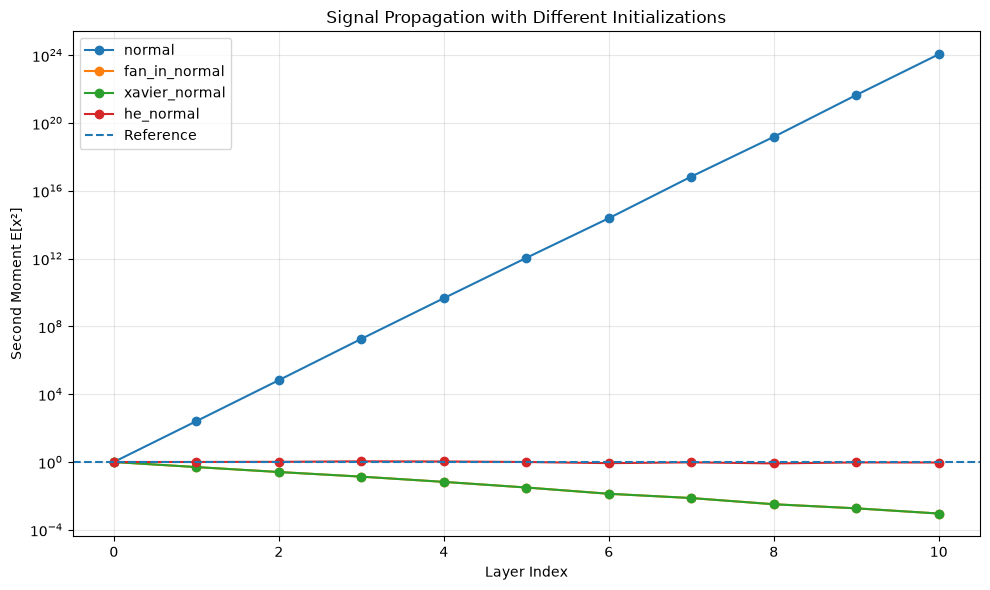

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

for method, moments in results.items():

    ax.plot(
        range(len(moments)),
        moments,
        marker="o",
        label=method
    )

ax.set_yscale("log")

ax.set_xlabel("Layer Index")
ax.set_ylabel("Second Moment E[x²]")

ax.set_title(
    "Signal Propagation with Different Initializations"
)

ax.axhline(
    y=1,
    linestyle="--",
    label="Reference"
)

ax.legend()
ax.grid(True, alpha=0.3)

fig.tight_layout()

output_path = (
    project_root / "results/figures/signal_propagation.png"
)

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [ ]:
import math

expected_stds = {
    "normal": 1.0,
    "fan_in_normal": math.sqrt(1 / 512),
    "xavier_normal": math.sqrt(2 / (512 + 512)),
    "he_normal": math.sqrt(2 / 512)
}

for method, expected in expected_stds.items():

    torch.manual_seed(42)

    layer = torch.nn.Linear(512, 512)

    initialize_weights(layer, method)

    actual = layer.weight.detach().std().item()

    print(f"Method: {method}")
    print(f"Expected std: {expected:.6f}")
    print(f"Actual std:   {actual:.6f}")
    print()

Method: normal
Expected std: 1.000000
Actual std:   1.001228

Method: fan_in_normal
Expected std: 0.044194
Actual std:   0.044248

Method: xavier_normal
Expected std: 0.044194
Actual std:   0.044248

Method: he_normal
Expected std: 0.062500
Actual std:   0.062577



In [ ]:
import numpy as np

fan_in = np.array(results["fan_in_normal"])
xavier = np.array(results["xavier_normal"])

print("Fan-in:", fan_in)
print("Xavier:", xavier)

print(
    "Maximum difference:",
    np.max(np.abs(fan_in - xavier))
)

assert np.allclose(fan_in, xavier)

print("Signal Propagation Consistency: PASS")

Fan-in: [1.00916576e+00 5.05766809e-01 2.58728862e-01 1.37962610e-01
 6.77095056e-02 3.15523744e-02 1.34626497e-02 7.52862822e-03
 3.24782915e-03 1.85948191e-03 9.19380982e-04]
Xavier: [1.00916576e+00 5.05766809e-01 2.58728862e-01 1.37962610e-01
 6.77095056e-02 3.15523744e-02 1.34626497e-02 7.52862822e-03
 3.24782915e-03 1.85948191e-03 9.19380982e-04]
Maximum difference: 0.0
Signal Propagation Consistency: PASS


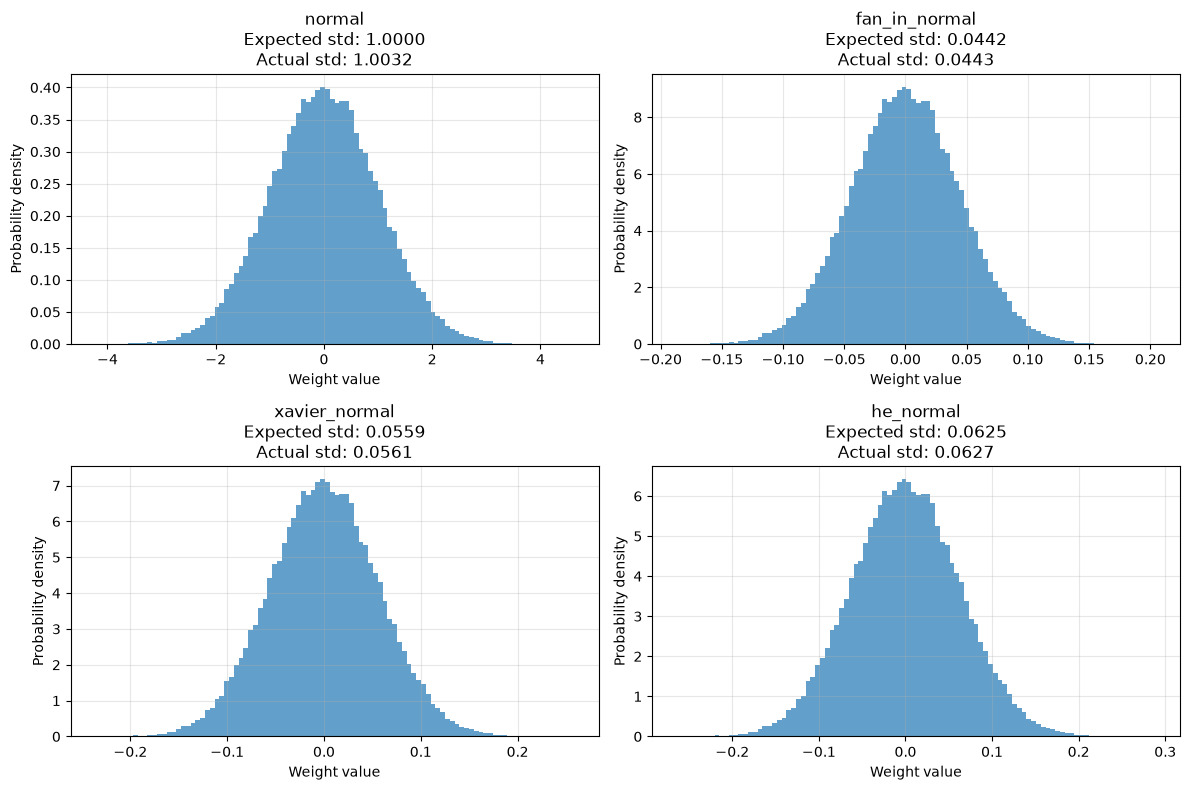

In [ ]:
import torch
import math
import matplotlib.pyplot as plt

from source.initialization import initialize_weights

fan_in = 512
fan_out = 128

methods = {
    "normal": 1.0,
    "fan_in_normal": math.sqrt(1 / fan_in),
    "xavier_normal": math.sqrt(2 / (fan_in + fan_out)),
    "he_normal": math.sqrt(2 / fan_in)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, (method, expected_std) in zip(
    axes.flat, methods.items()
):

    torch.manual_seed(42)

    layer = torch.nn.Linear(fan_in, fan_out)

    initialize_weights(layer, method)

    weights = layer.weight.detach().flatten().numpy()

    ax.hist(
        weights,
        bins=100,
        density=True,
        alpha=0.7
    )

    ax.set_title(
        f"{method}\n"
        f"Expected std: {expected_std:.4f}\n"
        f"Actual std: {weights.std():.4f}"
    )

    ax.set_xlabel("Weight value")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.3)

fig.tight_layout()

output_path = (
    project_root / "results/figures/initialization_distribution.png"
)

output_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(
    output_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()